<a href="https://colab.research.google.com/github/serenaycalisir/ml-calisma/blob/main/01_numpy_goruntu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

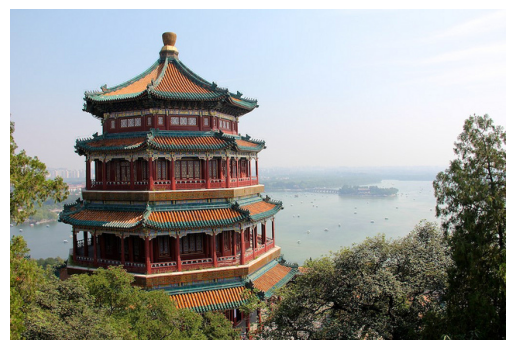

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_sample_image
img = load_sample_image("china.jpg").copy() # Bu örnek görüntü "salt okunur" geliyor.
# Kopyasını alarak üzerinde değişiklik yapabilir hâle getiriyoruz.
plt.imshow(img); plt.axis("off"); plt.show()

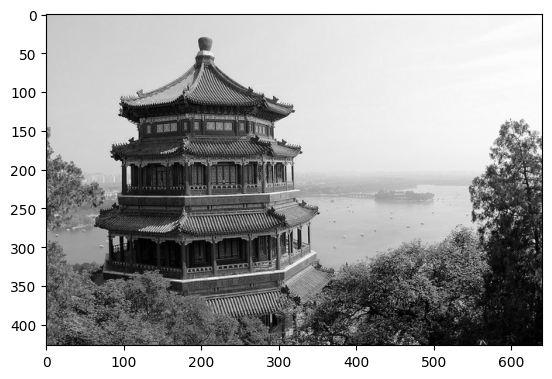

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 3 kanallı renkli resmi tek kanallı gri tonlamaya dönüştürüyoruz (Luminosity formülü)
gray_img = np.dot(img[...,:3], [0.2989, 0.5870, 0.1140])

# Tek kanallı resimde artık cmap="gray" parametresi çalışacaktır
plt.imshow(gray_img, cmap="gray")
plt.axis("on")
plt.show()

In [3]:
print(type(img))
print(img.shape)
print(img.ndim) # N-dimensional (boyutu)
print(img.size)
print(img.dtype)
print(img.min(), img.max()) #0=tam  siyah 255=tam beyaz
print(img[0,0])

<class 'numpy.ndarray'>
(427, 640, 3)
3
819840
uint8
0 255
[174 201 231]


In [4]:
# Sıfırdan dizi oluşturma
a = np.array([1, 2, 3])
print(a)
z = np.zeros((3, 4)) # 3x4 sıfır (float64)
print(z)
print(z.dtype)
print(z.shape)
o = np.ones((2, 2), dtype = np.uint8)
print(o)
print(o.size)
print(o.dtype)
r = np.arange(0, 10, 2) # [0 2 4 6 8]
print(r)
r2 = np.arange(4, 10, 1)
print(r2)
l = np.linspace(0, 1, 5) # 0'dan 1'e eşit aralıklı 5 sayı
print(l)
rnd = np.random.default_rng(42).integers(0, 256, size=(4, 4), dtype = np.uint8)
#Başındaki 42 (seed değeri) kod her çalıştığında tamamen aynı rastgele sayıların üretilmesini sağlar.
print(rnd)


[1 2 3]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
float64
(3, 4)
[[1 1]
 [1 1]]
4
uint8
[0 2 4 6 8]
[4 5 6 7 8 9]
[0.   0.25 0.5  0.75 1.  ]
[[136  38 217  22]
 [205 251  33 198]
 [193 255 145 167]
 [ 97  86  90 112]]


# **Veri Taşması (Overflow)**

In [5]:
x = np.array([250], dtype=np.uint8)
print(x+10) #255i aşınca başa sarar.

y=x.astype(np.int16) + 10 # önce daha geniş bir türe çevrilir.
print(np.clip(y, 0, 255).astype(np.uint8)) #Sonrasında tekrar eski formata döndürüyoruz.
print(y)


[4]
[255]
[260]


# **Görüntüyü Normalize Etme (Float Dönüşümü)**

Görüntüler üzerinde karmaşık matematiksel işlemler, filtrelemeler veya yapay zeka/derin öğrenme modelleri uygularken tam sayılarla çalışmak (yukarıda bahsettiğimiz taşma sorunları ve bölme işlemlerindeki yuvarlama hataları yüzünden) çok zordur.

Bu yüzden görüntünün piksellerini (0-255 arası)
önce float32 (ondalıklı sayı) formatına çeviririz.

Ardından 255 değerine bölerek tüm pikselleri 0.0 (tam siyah) ile 1.0 (tam beyaz) arasına sıkıştırırız (normalize ederiz). Bu işlem matematiksel hesaplamaların çok daha hassas ve hatasız yapılmasını sağlar.

In [6]:
#Bu yüzden görüntü üzerinde hesap yapmadan önce genelde floata çevrilir.

f = img.astype(np.float32) / 255
print(f.dtype, f.min(), f.max())

float32 0.0 1.0


# Örnekler

1.  100×256 boyutunda, soldan sağa siyahtan beyaza giden bir gri gradyan görüntüsü oluştur ve cmap="gray" ile çiz.

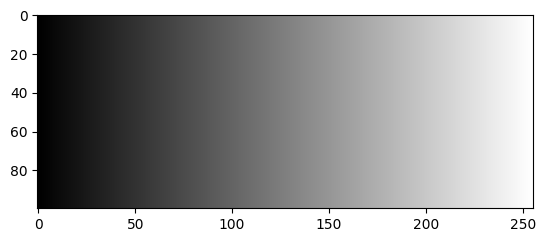

In [7]:
img = np.tile(np.arange(256, dtype=np.uint8), (100, 1)) #(100, 256)
plt.imshow(img, cmap ="gray")
plt.show()

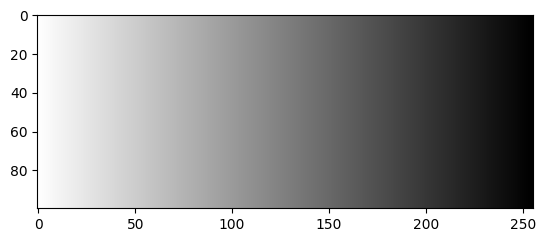

In [8]:
# Beyazdan siyaha (255'ten 0'a) azalan bir dizi oluşturuyoruz
inverted_range = 255 - np.arange(256, dtype=np.uint8)

# Yine 100 satır olacak şekilde alt alta kopyalıyoruz
img2 = np.tile(inverted_range, (100, 1))

plt.imshow(img2, cmap="gray")
plt.show()

In [9]:
dizi = np.arange(34)
print(dizi)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33]


2.   200×200×3 boyutunda, tamamen turuncu (R=255, G=165, B=0) bir görüntü oluştur ve çiz.



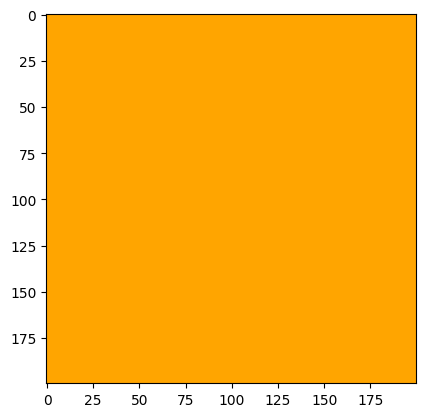

In [10]:
turuncu = np.array([255, 165, 0], dtype=np.uint8)
turuncu_resim = np.tile(turuncu, (200, 200, 1))
plt.imshow(turuncu_resim)
plt.show()

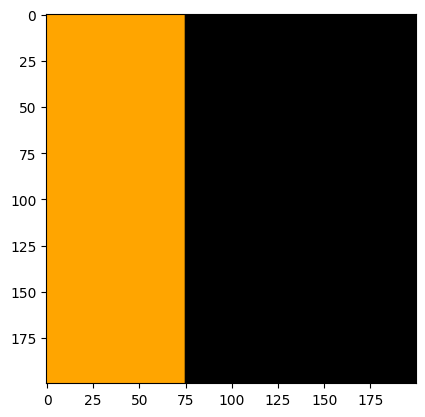

In [11]:
dizi = np.zeros((200, 200, 3), dtype=np.uint8)
dizi[:,:75]=[255, 165, 0]
plt.imshow(dizi)
plt.show()

3.   img'in parlaklığını 80 artır; taşmayı önlemeyi unutma. Orijinalle yan yana çiz.

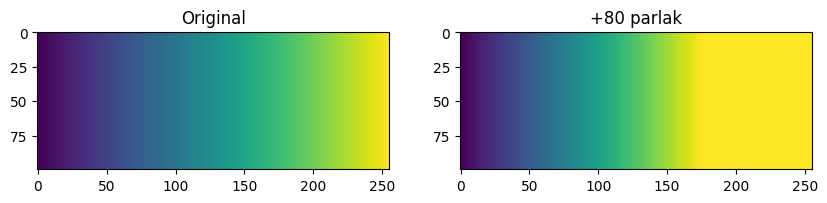

In [12]:
parlak = np.clip(img.astype(np.int16) + 80, 0, 255).astype(np.uint8)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(img); ax[0].set_title("Original")
ax[1].imshow(parlak); ax[1].set_title("+80 parlak")
plt.show()

np.clip(..., 0, 255): 80 ekledikten sonra bazı pikseller 255 sınırını aşmış (örneğin 300 olmuş) olabilir. np.clip fonksiyonu, 255'ten büyük olan tüm değerleri 255'e (tam beyaz), 0'dan küçük olanları ise 0'a (tam siyah) eşitler/sınırlar. Böylece taşmaların önüne geçilir.

plt.subplots(1, 2): Yan yana duracak şekilde 1 satır ve 2 sütundan oluşan bir grafik alanı oluşturur.

# Dilimleme (Slicing) - dizi[başlangıç:bitiş:adım]

img[y, x, c] - atır, sütun, kanal



(100, 100, 3)
(100, 100, 3) (107, 160, 3) (427, 640)


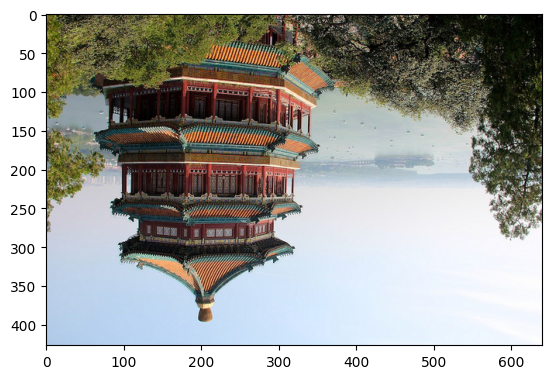

In [18]:
img = load_sample_image("china.jpg").copy()
h, w = img.shape[:2]
kirp = img[h//2-50 : h//2+50, w//2-50 : w//2+50]  #ortadan 100x100 kırp
print(kirp.shape)
dikey_ters = img[::-1]  #satırları ters çevir. -> dikey flip
ayna = img[:, ::-1]  #sütunları ters çevir. -> yatay flip
plt.imshow(dikey_ters)
kucuk = img[::4, ::4] #her 4 pikselden birini al -> 4 kat küçült.
R = img[:, :, 0]  #sadece kırmızı kanal -> (H,W)
print(kirp.shape, kucuk.shape, R.shape)




*   a[2] = 2.indeks (0'dan başlar.)
*   a[-1] = son eleman
*   a[2:5] = 2, 3, 4 (5 dahil değil)
*   a[:3] / a[3:] = İlk 3 / 3'ten sonrası
*   a[::2] = Birer atlayarak
*   a[::-1] = Ters sıra
*   a[:, 0] = Tüm satırların 0.sütunu












In [19]:
parca = img[:10, :10]  # Bu bir kopya değil, "görünüm-view"
parca[:] = 0           # Parçayı siyaha boya
print(img[:10, :10].max()) # 0 -> Orijinal de değişti.

img = load_sample_image("china.jpg").copy()   # görüntüyü geri yükle
guvenli = img[:10, :10].copy()                # bağımsız kopya istiyorsan .copy()

0


Kanallarla Oynamak

In [20]:
sadece_kirmizi = img.copy()
sadece_kirmizi[:,:,1:] = 0   # G ve B kanalları sıfırlanır

gri = (0.299*img[:, :, 0] + 0.587*img[:, :, 1] + 0.114*img[:, :, 2]).astype(np.uint8)
print(gri.shape)

(427, 640)


Boolean Maskeler: koşulla seçmek

bool 0.5595396662763467


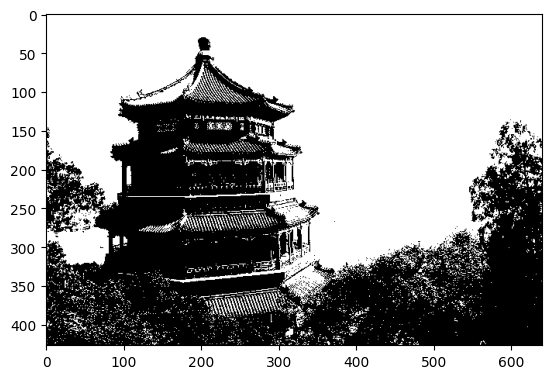

In [21]:
maske = gri > 128
print(maske.dtype, maske.mean())
ikili = np.where(maske, 255, 0).astype(np.uint8)   # (thresholding)
plt.imshow(ikili, cmap="gray"); plt.show()

# reshape, axis, broadcasting, vektörleşme

reshape ve transpose

In [22]:
kucuk = img[::8, ::8]  #Görüntünün çözünürlüğünü düşürerek veri boyutunu azaltır.
# ::8 adımı, dizide her 8 pikselde bir örnek al demektir.
duz = kucuk.reshape(-1) #Flatten (Çok boyutlu (3D) bir matrisi, yapay sinir ağlarının giriş katmanına verebilmek için tek boyutlu (1D) düz bir vektöre (sıralı liste haline) dönüştürmek.)
#-1 parametresi NumPy'a şu talimatı verir: "Geri kalan tüm boyutları çarp ve toplam eleman sayısını koruyacak şekilde tek bir satıra sığdır. Boyut hesabını benim yerime sen yap!"
print(duz.shape)

(12960,)


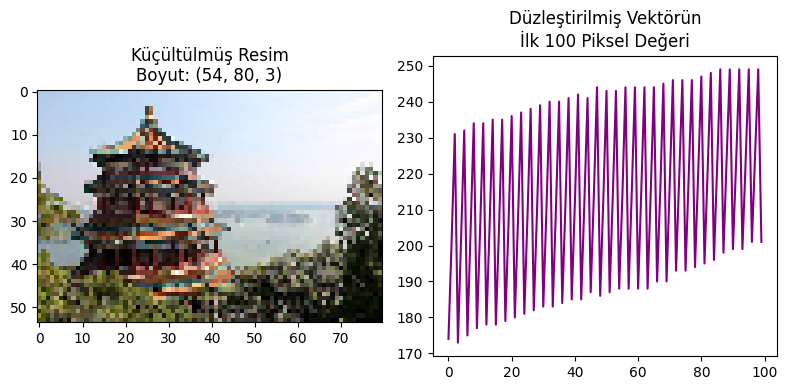

Orijinal piksel sayısı (3D): 54 x 80 x 3 = 12960
Düzleştirilmiş dizi boyutu (1D): (12960,)


In [23]:
# 1. Küçültülmüş görüntüyü gösterelim
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(kucuk)
plt.title(f"Küçültülmüş Resim\nBoyut: {kucuk.shape}")

# 2. Düzleştirilmiş vektörün ilk 15 piksel değerini yazdıralım
plt.subplot(1, 2, 2)
plt.plot(duz[:100], color='purple')
plt.title("Düzleştirilmiş Vektörün\nİlk 100 Piksel Değeri")
plt.tight_layout()
plt.show()

print(f"Orijinal piksel sayısı (3D): {kucuk.shape[0]} x {kucuk.shape[1]} x {kucuk.shape[2]} = {kucuk.size}")
print(f"Düzleştirilmiş dizi boyutu (1D): {duz.shape}")

In [24]:
batch = np.stack([kucuk, kucuk, kucuk])
print(batch.reshape(3, -1).shape)

chw = kucuk.transpose(2, 0, 1)
print(chw.shape)

(3, 12960)
(3, 54, 80)


axis: hangi boyut boyunca hesaplanacak?

Kural: axis=k verdiğin boyut yok olur (o boyut boyunca toplanır/ortalanır).

In [25]:
print(img.mean())                 # tek sayı: tüm piksellerin ortalaması
print(img.mean(axis=(0, 1)))      # (3,)    -> her KANALIN ortalaması [R G B]
print(img.mean(axis=2).shape)     # (H, W)  -> her PİKSELİN 3 kanal ortalaması (basit gri)
print(img.max(axis=0).shape)      # (W, 3)  -> her sütunun en büyük değeri

143.70232240437159
[144.71968311 145.46867681 140.91860729]
(427, 640)
(640, 3)


Broadcasting: farklı şekilleri otomatik eşleştirme

(427, 640, 3) boyutundaki bir diziden (3,) boyutundaki bir diziyi çıkarabilirsin: NumPy küçük diziyi her piksele "yayar". Kural: Şekiller sağdan karşılaştırılır; her boyut ya eşit olmalı ya da 1 olmalı.

In [26]:
f = img.astype(np.float32) / 255
ort = f.mean(axis=(0, 1))          # (3,)
std = f.std(axis=(0, 1))           # (3,)
norm = (f - ort) / std             # (H,W,3) - (3,) -> kanal başına standardizasyon
print(norm.mean(axis=(0, 1)).round(3), norm.std(axis=(0, 1)).round(3))   # ≈ [0 0 0] [1 1 1]

[-0.    -0.001 -0.   ] [1. 1. 1.]


Vektörleştirme: döngü yazma

In [27]:
import time

t = time.time()
ters = np.zeros_like(gri)
for i in range(gri.shape[0]):           # Python döngüsü
    for j in range(gri.shape[1]):
        ters[i, j] = 255 - gri[i, j]
t_dongu = time.time() - t

t = time.time()
ters2 = 255 - gri                        # vektörleştirilmiş
t_vek = time.time() - t

print(f"döngü: {t_dongu:.4f} sn | vektör: {t_vek:.6f} sn | {t_dongu/t_vek:.0f} kat hızlı")
print((ters == ters2).all())             # aynı sonuç

döngü: 0.1048 sn | vektör: 0.000119 sn | 879 kat hızlı
True
